# Day 81: Project 2 — Feature Engineering + Preprocessing

## Objective
- Clean the data: drop `customerID`, turn `TotalCharges` into numbers
- Binary-encode the Yes/No columns (and avoid a hidden trap)
- One-hot encode the multi-category columns with `drop_first`
- Build one leak-free `Pipeline` (`ColumnTransformer` then `XGBClassifier(scale_pos_weight=3)`)
- Check what class weighting and a few new features really do

> **Data:** the Telco Customer Churn sample dataset (7,043 customers). The file is not included in this folder.
> The notebook uses `data/` if it is there, otherwise it downloads a public copy. See `data/README.md`.
>
> **Test set rule:** I split off 20% of the customers first and do **not** touch them today. All comparisons use cross-validation on the training part only. The test set is for the final evaluation.

## Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split, StratifiedKFold, RepeatedStratifiedKFold, cross_validate

plt.style.use("seaborn-v0_8-darkgrid")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "axes.titlesize": 14, "axes.titleweight": "bold", "axes.labelsize": 11})
STAY, CHURN, GOLD, GREEN = "#0072B2", "#D55E00", "#E69F00", "#009E73"
Path("images").mkdir(exist_ok=True)

In [2]:
BASE = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

def load_telco():
    for name in ["WA_Fn-UseC_-Telco-Customer-Churn.csv", "Telco-Customer-Churn.csv"]:
        local = Path("data") / name
        if local.exists():
            return pd.read_csv(local)
    return pd.read_csv(BASE)

raw = load_telco()
print(raw.shape)

(7043, 21)


## 1. Drop `customerID`, make `TotalCharges` numeric (the pandas way)

In [3]:
step1 = raw.drop(columns="customerID")
step1["TotalCharges"] = pd.to_numeric(step1["TotalCharges"], errors="coerce")
print("Columns:", raw.shape[1], "->", step1.shape[1])
print("TotalCharges:", raw["TotalCharges"].dtype, "->", step1["TotalCharges"].dtype,
      "| missing values:", int(step1["TotalCharges"].isna().sum()))

Columns: 21 -> 20
TotalCharges: str -> float64 | missing values: 11


## 2. Binary encoding, and the 'No internet service' trap

In [4]:
addons = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
print("Values in OnlineSecurity:", sorted(step1["OnlineSecurity"].unique()))

# The roadmap's map({'Yes': 1, 'No': 0}) ...
naive = step1[addons].apply(lambda s: s.map({"Yes": 1, "No": 0}))
print("Naive map leaves NaN in each add-on column:", int(naive.isna().sum().iloc[0]))

# ... and where do those NaN come from?
no_internet = step1["InternetService"] == "No"
same = all((step1[c] == "No internet service").equals(no_internet) for c in addons)
print("'No internet service' rows = customers with InternetService 'No':", same)

Values in OnlineSecurity: ['No', 'No internet service', 'Yes']
Naive map leaves NaN in each add-on column: 1526
'No internet service' rows = customers with InternetService 'No': True


In [5]:
step2 = step1.copy()
for col in addons:
    step2[col] = step2[col].replace("No internet service", "No")     # same information as InternetService = No

yes_no = ["Partner", "Dependents", "PhoneService", "PaperlessBilling"] + addons
for col in yes_no:
    step2[col] = step2[col].map({"Yes": 1, "No": 0})
step2["gender"] = step2["gender"].map({"Male": 1, "Female": 0})
step2["Churn"] = step2["Churn"].map({"Yes": 1, "No": 0})

binary_cols = yes_no + ["gender", "Churn"]
print("NaN left after encoding:", int(step2[binary_cols].isna().sum().sum()))
print("Binary columns now hold only:", [int(v) for v in np.unique(step2[binary_cols].to_numpy())])

NaN left after encoding: 0
Binary columns now hold only: [0, 1]


Replacing "No internet service" with "No" loses nothing: those customers are exactly the ones with `InternetService = No`, and that column is kept.
(`MultipleLines` has a similar "No phone service" value. It stays as a category in the one-hot step, as in the roadmap.)

## 3. One-hot encoding with `drop_first=True`

In [6]:
cat4 = ["MultipleLines", "InternetService", "Contract", "PaymentMethod"]
step3 = pd.get_dummies(step2, columns=cat4, drop_first=True, dtype=int)
new = [c for c in step3.columns if c not in step2.columns]
print("Columns:", step2.shape[1], "->", step3.shape[1], "| new dummy columns:", len(new))
print("First two:", new[:2])

Columns: 20 -> 25 | new dummy columns: 9
First two: ['MultipleLines_No phone service', 'MultipleLines_Yes']


In [7]:
for col in cat4:
    kept = [c for c in new if c.startswith(col + "_")]
    first = sorted(step2[col].unique())[0]
    print(f"{col:16s} {step2[col].nunique()} categories -> {len(kept)} columns (reference category: '{first}')")

MultipleLines    3 categories -> 2 columns (reference category: 'No')
InternetService  3 categories -> 2 columns (reference category: 'DSL')
Contract         3 categories -> 2 columns (reference category: 'Month-to-month')
PaymentMethod    4 categories -> 3 columns (reference category: 'Bank transfer (automatic)')


`pd.get_dummies` on the whole table works here because the categories are fixed. But a real model gets **new** customers later, and a category might be missing or new.
That is why the real preprocessing goes **inside a pipeline** (next steps).

## 4. The reusable pipeline (saved to `churn_pipeline.py`)

In [8]:
%%writefile churn_pipeline.py
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

ADDONS = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
YES_NO = ["Partner", "Dependents", "PhoneService", "PaperlessBilling"] + ADDONS
NUMERIC = ["tenure", "MonthlyCharges", "TotalCharges"]
BINARY = ["SeniorCitizen", "gender"] + YES_NO
CATEGORICAL = ["MultipleLines", "InternetService", "Contract", "PaymentMethod"]
ENGINEERED_NUMERIC = ["n_addons", "avg_monthly_spend"]
ENGINEERED_BINARY = ["autopay"]


def clean_telco(df):
    """Raw Telco table in, clean table out (no learned statistics, so it cannot leak)."""
    out = df.drop(columns=["customerID", "Churn"], errors="ignore").copy()
    out["TotalCharges"] = pd.to_numeric(out["TotalCharges"], errors="coerce")    # blanks -> NaN
    for col in ADDONS:
        out[col] = out[col].replace("No internet service", "No")
    for col in YES_NO:
        out[col] = out[col].map({"Yes": 1, "No": 0})
    out["gender"] = out["gender"].map({"Male": 1, "Female": 0})
    return out


def clean_and_engineer(df):
    """Same cleaning, plus three simple new features."""
    out = clean_telco(df)
    out["n_addons"] = out[ADDONS].sum(axis=1)                                      # how many add-on services
    out["autopay"] = out["PaymentMethod"].str.contains("automatic").astype(int)    # pays automatically
    out["avg_monthly_spend"] = out["TotalCharges"] / out["tenure"].where(out["tenure"] > 0)
    return out


def build_pipeline(scale_pos_weight=3, engineered=False):
    numeric = NUMERIC + (ENGINEERED_NUMERIC if engineered else [])
    binary = BINARY + (ENGINEERED_BINARY if engineered else [])
    prep = ColumnTransformer([
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), numeric),
        ("bin", "passthrough", binary),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), CATEGORICAL),
    ])
    model = XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=3,
                          scale_pos_weight=scale_pos_weight, random_state=42, eval_metric="logloss")
    return Pipeline([
        ("clean", FunctionTransformer(clean_and_engineer if engineered else clean_telco)),
        ("prep", prep),
        ("model", model),
    ])


Writing churn_pipeline.py


The model settings (200 trees, learning rate 0.05, depth 3) are modest starting values chosen **before** looking at results, not tuned. Tuning comes later.

In [9]:
from churn_pipeline import build_pipeline, clean_telco, clean_and_engineer

y = (raw["Churn"] == "Yes").astype(int)
X = raw.drop(columns="Churn")
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print("Train:", X_train.shape, "| churn rate", round(y_train.mean(), 3))
print("Test: ", X_test.shape, "| churn rate", round(y_test.mean(), 3), "(set aside, not used today)")

Train: (5634, 20) | churn rate 0.265
Test:  (1409, 20) | churn rate 0.265 (set aside, not used today)


## 5. Build and fit the full pipeline (`ColumnTransformer` then `XGBClassifier(scale_pos_weight=3)`)

In [10]:
pipe = build_pipeline(scale_pos_weight=3)
pipe.fit(X_train, y_train)

names = pipe.named_steps["prep"].get_feature_names_out()
by_type = pd.Series([n.split("__")[0] for n in names]).value_counts()
print("Pipeline steps:", [name for name, _ in pipe.steps])
print("Raw columns in:", X_train.shape[1], "-> model features out:", len(names))
print("Features by type:", by_type.to_dict())

Pipeline steps: ['clean', 'prep', 'model']
Raw columns in: 20 -> model features out: 24
Features by type: {'bin': 12, 'cat': 9, 'num': 3}


## 6. What does class weighting do?

In [11]:
ratio = round((y_train == 0).sum() / (y_train == 1).sum(), 2)
print("Stayed : churned in the training data =", ratio, ": 1")

scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision",
           "precision": "precision", "recall": "recall", "f1": "f1"}
cv = StratifiedKFold(5, shuffle=True, random_state=42)

weight_results = {}
for weight in [1, ratio, 3]:
    out = cross_validate(build_pipeline(scale_pos_weight=weight), X_train, y_train, cv=cv, scoring=scoring)
    weight_results[weight] = {k: (out["test_" + k].mean(), out["test_" + k].std()) for k in scoring}

table = pd.DataFrame({f"weight={w}": {k: v[0] for k, v in r.items()} for w, r in weight_results.items()}).T
print(table.round(3).to_string())
print("Fold-to-fold std of ROC-AUC:", {f"w={w}": round(float(r["roc_auc"][1]), 3) for w, r in weight_results.items()})

Stayed : churned in the training data = 2.77 : 1


             roc_auc  pr_auc  precision  recall     f1
weight=1       0.848   0.667      0.670   0.520  0.586
weight=2.77    0.847   0.665      0.519   0.807  0.631
weight=3       0.847   0.665      0.509   0.823  0.629
Fold-to-fold std of ROC-AUC: {'w=1': 0.012, 'w=2.77': 0.012, 'w=3': 0.012}


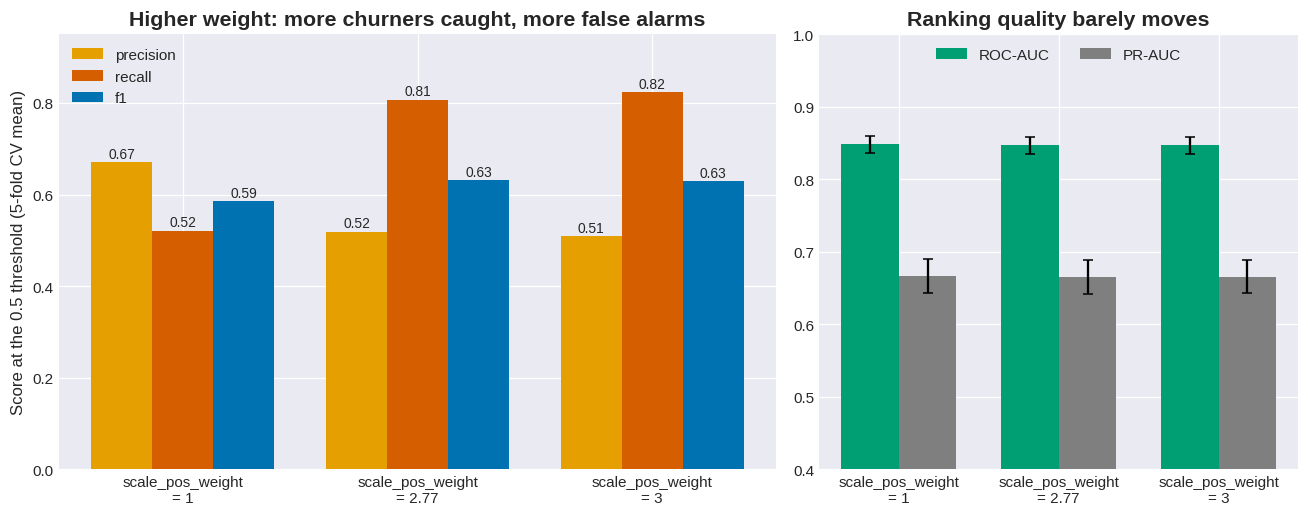

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [1.5, 1]})
labels = [f"scale_pos_weight\n= {w}" for w in weight_results]
x = np.arange(len(labels))
width = 0.26
for i, (metric, color) in enumerate([("precision", GOLD), ("recall", CHURN), ("f1", STAY)]):
    vals = [r[metric][0] for r in weight_results.values()]
    ax[0].bar(x + (i - 1) * width, vals, width, color=color, label=metric)
    for xi, v in zip(x + (i - 1) * width, vals):
        ax[0].text(xi, v + 0.01, f"{v:.2f}", ha="center", fontsize=9)
ax[0].set_xticks(x)
ax[0].set_xticklabels(labels)
ax[0].set_ylim(0, 0.95)
ax[0].set_title("Higher weight: more churners caught, more false alarms")
ax[0].set_ylabel("Score at the 0.5 threshold (5-fold CV mean)")
ax[0].legend(loc="upper left")

for i, (metric, color) in enumerate([("roc_auc", GREEN), ("pr_auc", "#7F7F7F")]):
    vals = [r[metric][0] for r in weight_results.values()]
    errs = [r[metric][1] for r in weight_results.values()]
    ax[1].bar(x + (i - 0.5) * 0.36, vals, 0.36, yerr=errs, color=color, capsize=3, label=metric.replace("_", "-").upper())
ax[1].set_xticks(x)
ax[1].set_xticklabels(labels)
ax[1].set_ylim(0.4, 1.0)
ax[1].set_title("Ranking quality barely moves")
ax[1].legend(loc="upper center", ncol=2)
plt.tight_layout()
plt.savefig("images/class_weight_comparison.png")
plt.show()

Class weights mostly **shift the balance** between recall and precision at the default 0.5 threshold. They do little to the ranking quality (ROC-AUC, PR-AUC).
That is a hint that **threshold tuning** can do much of the same job. Which balance is right depends on the cost of a missed churner vs a wasted offer.

## 7. Do three simple new features help?

`n_addons` (how many of the 6 add-on services), `autopay` (pays by automatic bank transfer or credit card), and `avg_monthly_spend` (`TotalCharges / tenure`).
Test them fairly: same folds for both versions, repeated 5-fold x 3, then compare **fold by fold**.

In [13]:
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
base = cross_validate(build_pipeline(3, engineered=False), X_train, y_train, cv=rcv, scoring=scoring)
eng = cross_validate(build_pipeline(3, engineered=True), X_train, y_train, cv=rcv, scoring=scoring)

for name, out in [("base (24 features)", base), ("with 3 new features", eng)]:
    print(f"{name:20s} ROC-AUC {out['test_roc_auc'].mean():.3f} +/- {out['test_roc_auc'].std():.3f}"
          f" | PR-AUC {out['test_pr_auc'].mean():.3f} +/- {out['test_pr_auc'].std():.3f}")

for metric in ["roc_auc", "pr_auc"]:
    diff = eng["test_" + metric] - base["test_" + metric]
    print(f"{metric}: mean difference {diff.mean():+.4f} (std {diff.std():.4f}), new features better in {int((diff > 0).sum())} of {len(diff)} folds")

base (24 features)   ROC-AUC 0.847 +/- 0.013 | PR-AUC 0.665 +/- 0.021
with 3 new features  ROC-AUC 0.847 +/- 0.013 | PR-AUC 0.663 +/- 0.021
roc_auc: mean difference -0.0001 (std 0.0009), new features better in 6 of 15 folds
pr_auc: mean difference -0.0022 (std 0.0046), new features better in 5 of 15 folds


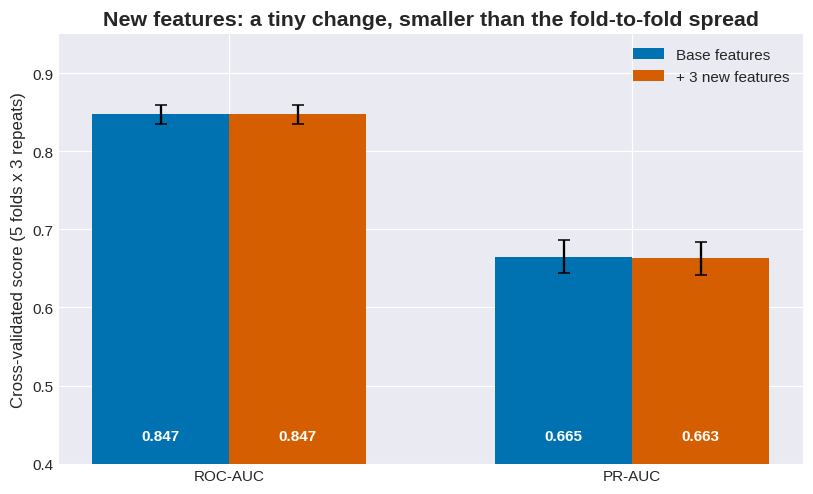

In [14]:
fig, ax = plt.subplots(figsize=(7.5, 4.6))
x = np.arange(2)
for i, (name, out, color) in enumerate([("Base features", base, STAY), ("+ 3 new features", eng, CHURN)]):
    vals = [out["test_roc_auc"].mean(), out["test_pr_auc"].mean()]
    errs = [out["test_roc_auc"].std(), out["test_pr_auc"].std()]
    ax.bar(x + (i - 0.5) * 0.34, vals, 0.34, yerr=errs, color=color, capsize=4, label=name)
    for xi, v in zip(x + (i - 0.5) * 0.34, vals):
        ax.text(xi, 0.43, f"{v:.3f}", ha="center", color="white", fontweight="bold", fontsize=10)
ax.set_xticks(x)
ax.set_xticklabels(["ROC-AUC", "PR-AUC"])
ax.set_ylim(0.4, 0.95)
ax.set_title("New features: a tiny change, smaller than the fold-to-fold spread")
ax.set_ylabel("Cross-validated score (5 folds x 3 repeats)")
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig("images/engineered_features_effect.png")
plt.show()

## 8. Where does a simple rule stand next to the pipeline?

In [15]:
from sklearn.metrics import precision_score, recall_score, f1_score

rule = (X_train["Contract"] == "Month-to-month").astype(int)
rows = {"Month-to-month rule (train)": [precision_score(y_train, rule), recall_score(y_train, rule), f1_score(y_train, rule)]}
w3 = weight_results[3]
rows["XGBoost pipeline, weight 3 (CV)"] = [w3["precision"][0], w3["recall"][0], w3["f1"][0]]
print(pd.DataFrame(rows, index=["precision", "recall", "f1"]).T.round(3).to_string())

                                 precision  recall     f1
Month-to-month rule (train)          0.427   0.887  0.577
XGBoost pipeline, weight 3 (CV)      0.509   0.823  0.629


## 9. What does the model use? (top features)

Contract_Two year                 0.326
Contract_One year                 0.196
InternetService_Fiber optic       0.136
InternetService_No                0.075
StreamingMovies                   0.043
PaymentMethod_Electronic check    0.038
tenure                            0.035
OnlineSecurity                    0.024
PaperlessBilling                  0.020
TechSupport                       0.011


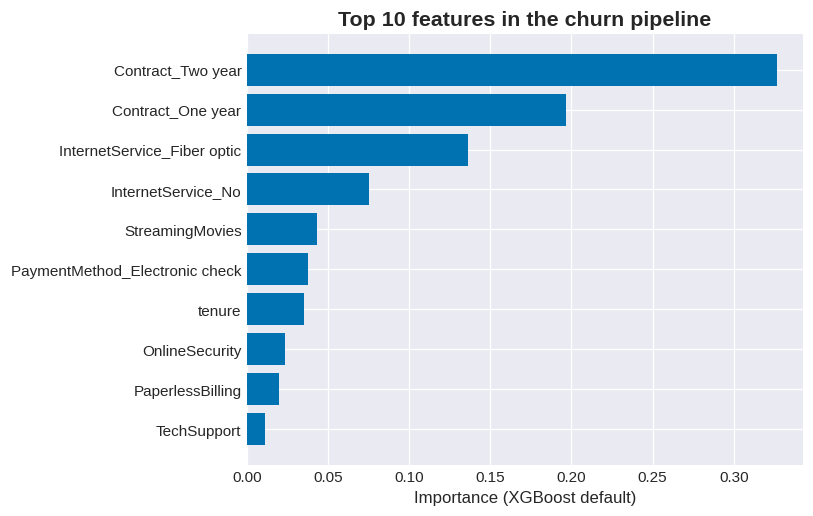

In [16]:
importance = pd.Series(pipe.named_steps["model"].feature_importances_, index=[n.split("__")[1] for n in names])
top10 = importance.sort_values(ascending=False).head(10)
print(top10.round(3).to_string())

plt.figure(figsize=(7.5, 4.8))
plt.barh(top10.index[::-1], top10.values[::-1], color=STAY)
plt.xlabel("Importance (XGBoost default)")
plt.title("Top 10 features in the churn pipeline")
plt.tight_layout()
plt.savefig("images/feature_importance_churn.png")
plt.show()

## Practice Exercise
Is `TotalCharges` just `tenure x MonthlyCharges`? Check the correlation, and the typical gap.

In [17]:
clean = clean_telco(raw)
expected = clean["tenure"] * clean["MonthlyCharges"]
ok = clean["TotalCharges"].notna()
print("Correlation(TotalCharges, tenure x MonthlyCharges):", round(clean.loc[ok, "TotalCharges"].corr(expected[ok]), 3))
print("Median absolute gap:", round((clean.loc[ok, "TotalCharges"] - expected[ok]).abs().median(), 1), "dollars")
print("Correlation(TotalCharges, tenure):", round(clean.loc[ok, "TotalCharges"].corr(clean.loc[ok, "tenure"]), 3))

Correlation(TotalCharges, tenure x MonthlyCharges): 1.0
Median absolute gap: 28.6 dollars
Correlation(TotalCharges, tenure): 0.826


## Mini Challenge
Can the pipeline score a brand-new customer straight from raw data, even with a payment method it has never seen and a blank `TotalCharges`?

In [18]:
new_customer = pd.DataFrame([{
    "customerID": "NEW-0001", "gender": "Female", "SeniorCitizen": 0, "Partner": "No", "Dependents": "No",
    "tenure": 0, "PhoneService": "Yes", "MultipleLines": "No", "InternetService": "Fiber optic",
    "OnlineSecurity": "No", "OnlineBackup": "No", "DeviceProtection": "No", "TechSupport": "No",
    "StreamingTV": "Yes", "StreamingMovies": "Yes", "Contract": "Month-to-month", "PaperlessBilling": "Yes",
    "PaymentMethod": "Crypto wallet", "MonthlyCharges": 95.5, "TotalCharges": " ",
}])
prob = pipe.predict_proba(new_customer)[0, 1]
print("Churn probability for the new customer:", round(float(prob), 3))
print("Unseen payment method and blank TotalCharges handled without an error")

Churn probability for the new customer: 0.923
Unseen payment method and blank TotalCharges handled without an error


/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_encoders.py:261: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


## Summary
- `customerID` dropped, `TotalCharges` converted (11 blanks become NaN, then median-filled inside the pipeline)
- The roadmap's `map({'Yes': 1, 'No': 0})` would silently create NaN in the 6 add-on columns (1,526 each), because of the "No internet service" value
- One-hot with `drop_first` turns 4 columns into 9, giving 24 model features in total
- One pipeline from raw table to prediction: cleaning, `ColumnTransformer`, `XGBClassifier(scale_pos_weight=3)`
- Class weights move the recall/precision balance but barely change ranking quality
- Three new features made almost no difference
- The test set is still untouched. Next: Day 82, model comparison and the final test evaluation